# Is the mtDSB oligodendrocyte response specific, or the generic injured-OL response of EAE?

Responder oligodendrocytes switch on a stress programme, become immune-visible and lose myelin genes (finding 2).
Damaged OLs in neuroinflammation (disease-associated OLs, DAOs) are also immune-visible. The RR-map EAE atlas was run
on the **same 5k Xenium panel**, so the two can be compared gene for gene without cross-panel mapping.

* **EAE data:** spinal cord, 8 control (CFA) and 59 EAE mice, chronic (MOG) and relapsing-remitting (PLP) models,
  onset to remission; OLs annotated MOL / DAO / NFOL; curated niche states (lesion active / progressive / mixed,
  normal-appearing "physiological").
* **Contrasts (per mouse, log2 CPM of pseudobulked OLs):** mtDSB responders vs same-slide controls (3 vs 6; DA-OL
  folded into OL); EAE OLs in lesions vs control OLs; EAE OLs in normal-appearing tissue vs control OLs; DAO vs MOL
  within EAE mice.

Caveats: brain vs spinal cord; 42 days after induction vs weeks of EAE; lesion OLs sit among dense immune cells, so
some myeloid transcripts (Aif1, Ctss, Itgam) spill into them in segmentation.

| input | made by | where |
|---|---|---|
| `results/eae_comparison/eae_*` | `scripts/export_eae_pseudobulk.py --h5ad <RRMAP2 ... Anno2to4Updated.h5ad>` | laptop, 10 min |
| `results/region_time/pseudobulk_counts.csv` | `scripts/run_region_time_de.py` | office Mac |

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils.ol_response import ISR_GENES
from utils.gene_sets import GENE_SETS

IN = REPO / "results" / "eae_comparison"; FIG = IN / "figures"; TAB = IN / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]
drivers = pd.read_csv(REPO / "results" / "ol_gene_drivers" / "tables" / "driver_genes.csv", index_col=0)
pm = pd.read_csv(REPO / "results" / "region_time" / "pseudobulk_meta.csv", index_col=0)
pc = pd.read_csv(REPO / "results" / "region_time" / "pseudobulk_counts.csv", index_col=0).loc[pm.index]
em = pd.read_csv(IN / "eae_pseudobulk_meta.csv", index_col=0)
ec = pd.read_csv(IN / "eae_pseudobulk_counts.csv.gz", index_col=0).loc[em.index]
LES = ["Lesion_active", "Lesion_progressive", "Lesion_mix"]

def logcpm(df):
    return np.log2(1 + 1e6 * df.div(df.sum(1), axis=0))
def mtdsb_lfc(types):
    # responders - controls of the same slide (age), averaged over the two slides
    m = pm[pm.cell_type.isin(types)]; c = pc.loc[m.index].groupby(m.sample_id).sum(); L = logcpm(c)
    d = [L.loc[[s for s in sections.index[sections.age == a] if grp[s] == "responder"]].mean()
         - L.loc[[s for s in sections.index[sections.age == a] if grp[s] == "control"]].mean() for a in (21, 60)]
    return pd.concat(d, axis=1).mean(1), c.sum() / c.sum().sum() * 1e6
def eae_lfc(l1, case, ctrl, l2=None):
    m = em[(em.Anno_L1_curated == l1) & (em.Anno_L2.isin(l2) if l2 else True)]
    a, b = m[case(m)], m[ctrl(m)]
    return logcpm(ec.loc[a.index].groupby(a.sample_name).sum()).mean() - logcpm(ec.loc[b.index].groupby(b.sample_name).sum()).mean()

OLS = ["MOL", "DAO", "NFOL"]
mt_ol, ol_cpm = mtdsb_lfc(["Oligodendrocytes", "DA-Oligodendrocytes"])
lfc = pd.DataFrame({
    "mtDSB responders": mt_ol,
    "EAE lesion": eae_lfc("Oligodendrocyte", lambda m: (m.condition == "EAE") & m.Curated_niche_state.isin(LES), lambda m: m.condition == "CONTROL", OLS),
    "EAE normal-appearing": eae_lfc("Oligodendrocyte", lambda m: (m.condition == "EAE") & (m.Curated_niche_state == "Physiological"), lambda m: m.condition == "CONTROL", OLS)})
m = em[(em.Anno_L1_curated == "Oligodendrocyte") & (em.condition == "EAE")]
A = logcpm(ec.loc[m[m.Anno_L2 == "DAO"].index].groupby(m[m.Anno_L2 == "DAO"].sample_name).sum())
B = logcpm(ec.loc[m[m.Anno_L2 == "MOL"].index].groupby(m[m.Anno_L2 == "MOL"].sample_name).sum())
mice = A.index.intersection(B.index); lfc["DAO vs MOL"] = (A.loc[mice] - B.loc[mice]).mean()
expressed = ol_cpm[ol_cpm > 20].index
lfc = lfc.loc[expressed]
lfc["programme"] = drivers.programme.reindex(lfc.index)
save_table = lambda df, name, index=True: (df.to_csv(TAB / f"{name}.csv", index=index), df)[1]
save_table(lfc.round(3), "ol_log2fc_mtdsb_vs_eae")

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
PROG_COL = {"ATF4 / integrated stress response": "#d62728", "cell cycle / survival": "#9467bd", "immune / reactive": "#2ca02c",
            "mitochondrial & protein quality control": "#8c564b", "cytoskeleton / adhesion": "#17becf", "lipid / transport": "#bcbd22",
            "mature OL / myelin (down)": "#1f77b4", "OL lineage / immature": "#e377c2", "other": "#7f7f7f"}
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
print(f"{len(expressed)} genes expressed in mtDSB OLs (> 20 CPM); EAE mice: {em[em.condition == 'EAE'].sample_name.nunique()}, controls: {em[em.condition == 'CONTROL'].sample_name.nunique()}")

2967 genes expressed in mtDSB OLs (> 20 CPM); EAE mice: 59, controls: 8


## A. Gene by gene: mtDSB responder OLs against EAE OLs

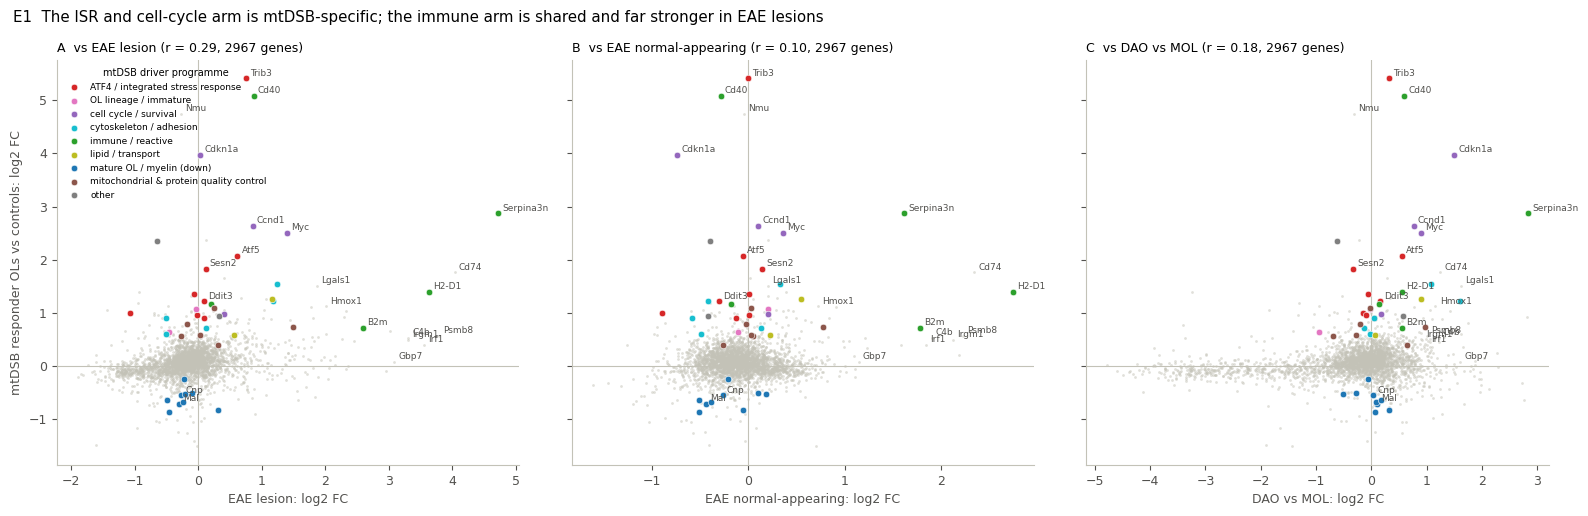

In [2]:
LABEL = ["Trib3", "Gdf15", "Atf5", "Ddit3", "Eif4ebp1", "Sesn2", "Cdkn1a", "Ccnd1", "Cd40", "Nmu", "Serpina3n", "Cd74",
         "H2-D1", "B2m", "Psmb8", "Irf1", "C4b", "Gbp7", "Irgm1", "Hmox1", "Lgals1", "Myc", "Mal", "Cnp"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
for ax, col in zip(axes, ["EAE lesion", "EAE normal-appearing", "DAO vs MOL"]):
    bg = lfc[lfc.programme.isna()]
    ax.scatter(bg[col], bg["mtDSB responders"], s=4, c=GREY, alpha=0.5, linewidths=0, rasterized=True)
    for prog, d in lfc[lfc.programme.notna()].groupby("programme"):
        ax.scatter(d[col], d["mtDSB responders"], s=22, c=PROG_COL[prog], label=prog, zorder=3, edgecolors="white", linewidths=0.4)
    for gname in LABEL:
        if gname in lfc.index:
            ax.annotate(gname, (lfc.loc[gname, col], lfc.loc[gname, "mtDSB responders"]), fontsize=6.5, color=INK2, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0, color=AXIS, lw=0.8); ax.axvline(0, color=AXIS, lw=0.8)
    r = np.corrcoef(lfc[col], lfc["mtDSB responders"])[0, 1]
    ax.set_xlabel(f"{col}: log2 FC"); ax.set_title(f"{'ABC'[['EAE lesion', 'EAE normal-appearing', 'DAO vs MOL'].index(col)]}  vs {col} (r = {r:.2f}, {len(lfc)} genes)", fontsize=9)
axes[0].set_ylabel("mtDSB responder OLs vs controls: log2 FC")
axes[0].legend(frameon=False, fontsize=6.5, loc="upper left", title="mtDSB driver programme", title_fontsize=7)
fig.suptitle("E1  The ISR and cell-cycle arm is mtDSB-specific; the immune arm is shared and far stronger in EAE lesions", x=0.01, ha="left")
fig.tight_layout(); save(fig, "E1_gene_scatter")

**A.** Genome-wide the two responses are only loosely related (r = 0.29 against EAE lesion OLs, 0.10 against
normal-appearing EAE OLs, 0.18 against DAO vs MOL). The structure is clear from the driver programmes:
* **mtDSB-specific:** the ATF4 / integrated stress response (Trib3 +5.4 log2 in mtDSB vs +0.8 in EAE lesions, Gdf15
  +4.5 vs 0.0, Atf5, Ddit3, Eif4ebp1, Sesn2) and the cell-cycle / survival genes (Cdkn1a = p21 +4.0 vs 0.0, Ccnd1),
  plus Cd40 and Nmu. EAE OLs barely touch these at any stage (C below).
* **Shared:** Serpina3n, Cd74, H2-D1 / B2m, Lgals1, Hmox1, Myc, Flna, Abca1: a generic injured / immune-visible OL core.
* **EAE-specific:** an interferon-gamma programme (Irf1, Psmb8, Gbp7, Irgm1 / 2, C4b, H2-K1; +3-4 log2 in lesions),
  hardly induced in mtDSB OLs, and myeloid spill-over (Aif1, Ctss, Itgam) in dense lesions.

## B. Programme by programme

,mtDSB responders,EAE lesion,EAE normal-appearing,DAO vs MOL,n_genes
ATF4 / integrated stress response,1.85,0.06,-0.15,0.06,8
cell cycle / survival,2.52,0.67,-0.02,0.83,4
immune / reactive,2.25,2.41,1.13,0.94,5
mitochondrial & protein quality control,0.69,0.28,0.10,0.07,6
mature OL / myelin (down),-0.62,-0.22,-0.23,-0.00,9
"ISR (prespecified, 10 genes)",1.83,0.21,-0.02,0.02,6
MHC class I,0.83,3.27,2.26,0.65,4
interferon (type I),0.19,1.27,0.22,0.84,2
"IFN-gamma (Irf1, Gbp, Irgm, Psmb8/9, Cxcl9/10, Stat1)",0.32,3.11,1.72,1.00,6
myelin (prespecified),-0.49,-0.15,-0.37,0.23,13


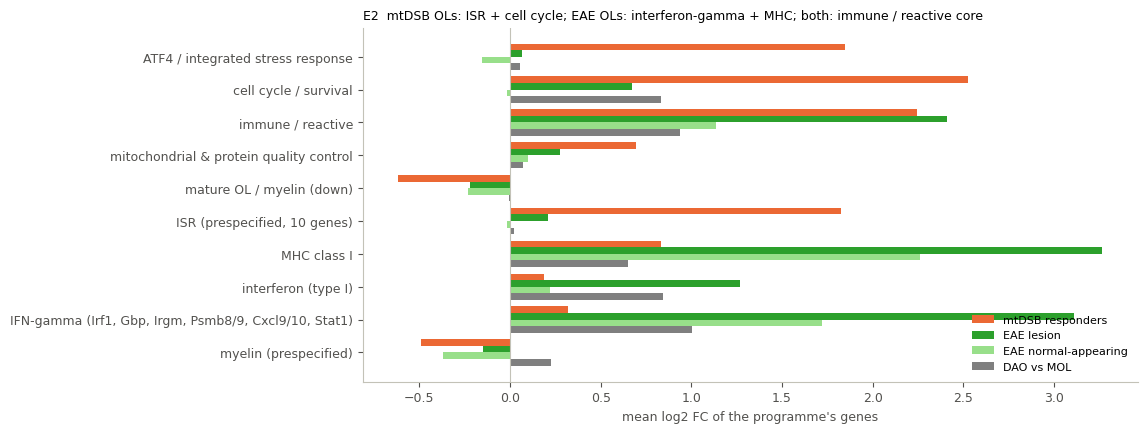

In [3]:
PROGS = {**{p: list(drivers.index[drivers.programme == p]) for p in ["ATF4 / integrated stress response", "cell cycle / survival",
         "immune / reactive", "mitochondrial & protein quality control", "mature OL / myelin (down)"]},
         "ISR (prespecified, 10 genes)": ISR_GENES, "MHC class I": GENE_SETS["MHC1"], "interferon (type I)": GENE_SETS["IFN"],
         "IFN-gamma (Irf1, Gbp, Irgm, Psmb8/9, Cxcl9/10, Stat1)": ["Irf1", "Gbp2", "Gbp7", "Irgm1", "Irgm2", "Psmb8", "Psmb9", "Cxcl9", "Cxcl10", "Stat1"],
         "myelin (prespecified)": GENE_SETS["MYELIN"]}
cols = ["mtDSB responders", "EAE lesion", "EAE normal-appearing", "DAO vs MOL"]
prog = pd.DataFrame({k: lfc.loc[[g for g in v if g in lfc.index], cols].mean() for k, v in PROGS.items()}).T
prog["n_genes"] = [len([g for g in v if g in lfc.index]) for v in PROGS.values()]
display(save_table(prog.round(2), "programme_log2fc"))
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(prog)); h = 0.2
for i, (c, col) in enumerate(zip(cols, [ORANGE, "#2ca02c", "#98df8a", "#7f7f7f"])):
    ax.barh(y + (i - 1.5) * h, prog[c], h, color=col, label=c)
ax.set_yticks(y, prog.index); ax.invert_yaxis(); ax.axvline(0, color=AXIS, lw=0.8)
ax.set_xlabel("mean log2 FC of the programme's genes"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("E2  mtDSB OLs: ISR + cell cycle; EAE OLs: interferon-gamma + MHC; both: immune / reactive core", fontsize=9)
save(fig, "E2_programmes")

**B.** The ISR programme is up ~1.8 log2 (3.5x) in mtDSB responder OLs and ~0.1-0.2 in EAE lesion OLs (0 in DAOs);
cell cycle / p21 2.5 vs 0.7. The other way round, interferon-gamma genes are up 3.1 log2 in EAE lesion OLs and 0.3 in
mtDSB, MHC class I 3.3 vs 0.8. The immune / reactive driver genes are up equally in both (2.3 vs 2.4). Myelin genes
drop more in mtDSB responders than in EAE lesion OLs (lesion OL pools also hold surviving and newly formed OLs).
Programmes are averaged over their genes expressed > 20 CPM in mtDSB OLs (`n_genes`).

## C. Does any EAE stage switch on the ISR? Per-mouse OL scores against each study's own controls

/var/folders/5b/5bpdw2nj10d6gxym7gcl01hh0000gp/T/ipykernel_11578/1770605717.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  olm["ISR_z"] = olm.groupby("age", group_keys=False).apply(lambda d: (d.ISR - d.ISR[d.group == "control"].mean()) / d.ISR[d.group == "control"].std())


EAE per-mouse OL ISR z: max 4.1 | mtDSB responders: [3.99, 8.88, 6.36]


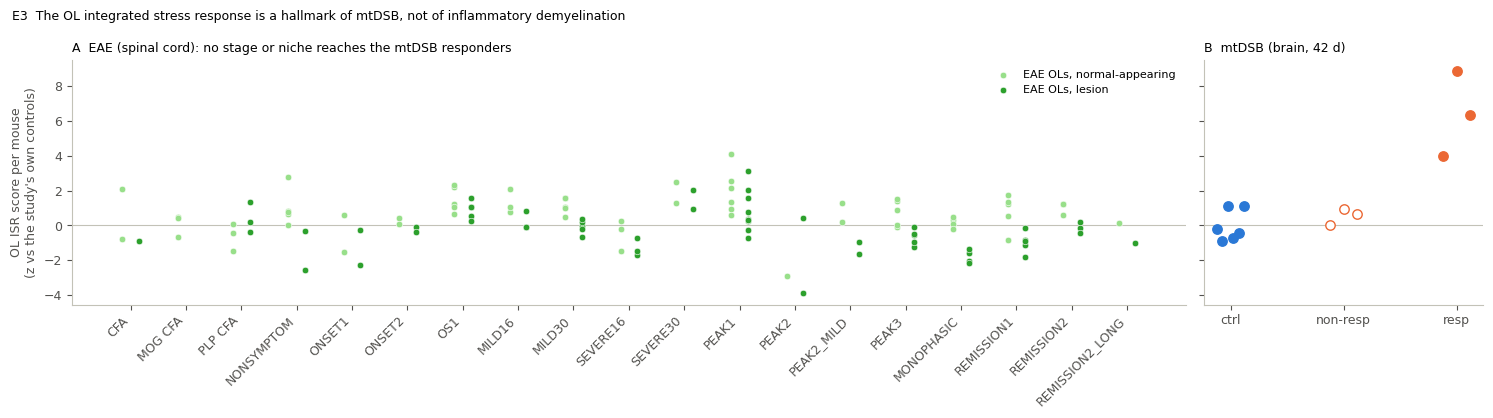

In [4]:
cs = pd.read_csv(IN / "eae_cell_scores.csv.gz", usecols=["sample_name", "condition", "model", "stage", "Anno_L1_curated", "Curated_niche_state", "ISR", "drivers_up", "MHC1"])
o = cs[cs.Anno_L1_curated == "Oligodendrocyte"].copy()
o["niche"] = np.where(o.Curated_niche_state.isin(LES), "lesion", np.where(o.Curated_niche_state == "Physiological", "normal-appearing", "other"))
pmouse = o[o.niche != "other"].groupby(["sample_name", "niche"]).agg(ISR=("ISR", "mean"), MHC1=("MHC1", "mean"), n=("ISR", "size"),
                                                                      stage=("stage", "first"), model=("model", "first"), condition=("condition", "first")).reset_index()
pmouse = pmouse[pmouse.n >= 50]
ctrl = pmouse[pmouse.condition == "CONTROL"]
for k in ["ISR", "MHC1"]:
    pmouse[f"{k}_z"] = (pmouse[k] - ctrl[k].mean()) / ctrl[k].std()
olm = pd.read_csv(REPO / "results" / "cell_table" / "ol_gene_scores.csv.gz").groupby("sample_id")["isr"].mean().rename("ISR").to_frame()
olm["group"] = grp; olm["age"] = sections.age
olm["ISR_z"] = olm.groupby("age", group_keys=False).apply(lambda d: (d.ISR - d.ISR[d.group == "control"].mean()) / d.ISR[d.group == "control"].std())
save_table(pmouse.round(3), "eae_per_mouse_ol_scores", index=False); save_table(olm.round(3), "mtdsb_per_mouse_ol_isr")

STAGES = ["CFA", "MOG CFA", "PLP CFA", "NONSYMPTOM", "ONSET1", "ONSET2", "OS1", "MILD16", "MILD30", "SEVERE16", "SEVERE30",
          "PEAK1", "PEAK2", "PEAK2_MILD", "PEAK3", "MONOPHASIC", "REMISSION1", "REMISSION2", "REMISSION2_LONG"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [4, 1]}, sharey=True)
ax = axes[0]
for j, (niche, col) in enumerate([("normal-appearing", "#98df8a"), ("lesion", "#2ca02c")]):
    d = pmouse[pmouse.niche == niche]
    x = d.stage.map({s: i for i, s in enumerate(STAGES)}) + (j - 0.5) * 0.3
    ax.scatter(x, d.ISR_z, s=22, c=col, label=f"EAE OLs, {niche}", edgecolors="white", linewidths=0.4, zorder=3)
ax.set_xticks(range(len(STAGES)), STAGES, rotation=45, ha="right"); ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylabel("OL ISR score per mouse\n(z vs the study's own controls)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("A  EAE (spinal cord): no stage or niche reaches the mtDSB responders", fontsize=9)
ax = axes[1]
for gi, g in enumerate(["control", "non-responder", "responder"]):
    v = olm[olm.group == g].ISR_z
    ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, zorder=3,
               **({"color": BLUE} if g == "control" else {"facecolor": "white", "edgecolor": ORANGE} if g == "non-responder" else {"color": ORANGE}))
ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.axhline(0, color=AXIS, lw=0.8)
ax.set_title("B  mtDSB (brain, 42 d)", fontsize=9)
fig.suptitle("E3  The OL integrated stress response is a hallmark of mtDSB, not of inflammatory demyelination", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); save(fig, "E3_isr_by_stage")
print("EAE per-mouse OL ISR z: max", pmouse[pmouse.condition == "EAE"].ISR_z.max().round(2), "| mtDSB responders:", olm[olm.group == "responder"].ISR_z.round(2).tolist())

**C.** Across 59 EAE mice, from pre-symptomatic to remission, the mean OL ISR score stays within ~-4 to +4 SD of the
EAE controls (mostly -2 to +2) in both lesions and normal-appearing tissue, while the three mtDSB responders sit at +4 to +9 SD of
theirs (non-responders within the control range). The z-scales differ in precision (8 EAE controls; 3 controls per
mtDSB slide), but the gene-level fold changes in A / B agree: inflammatory demyelination does not drive the OL ISR.

## D. Microglia and astrocytes: is the glial reaction the same?

In [5]:
rows = {}
for name, mt_types, l1, l2 in [("Microglia", ["Microglia"], "Myeloid", ["Microglia"]), ("Astrocytes", ["Astrocytes"], "Astrocyte", None)]:
    mt, cpm = mtdsb_lfc(mt_types)
    e = eae_lfc(l1, lambda m: (m.condition == "EAE") & m.Curated_niche_state.isin(LES), lambda m: m.condition == "CONTROL", l2)
    g = cpm[cpm > 20].index
    rows[name] = {"r_all_genes": np.corrcoef(mt[g], e[g])[0, 1], "n_genes": len(g),
                  **{f"{k} mtDSB": mt[[x for x in GENE_SETS[k] if x in mt.index]].mean() for k in ["DAM", "HOMEOSTATIC", "MHC1", "IFN", "ASTRO_REACTIVE"]},
                  **{f"{k} EAE lesion": e[[x for x in GENE_SETS[k] if x in e.index]].mean() for k in ["DAM", "HOMEOSTATIC", "MHC1", "IFN", "ASTRO_REACTIVE"]}}
glia = save_table(pd.DataFrame(rows).T.round(2), "glia_programmes")
display(glia)

,r_all_genes,n_genes,DAM mtDSB,HOMEOSTATIC mtDSB,MHC1 mtDSB,IFN mtDSB,ASTRO_REACTIVE mtDSB,DAM EAE lesion,HOMEOSTATIC EAE lesion,MHC1 EAE lesion,IFN EAE lesion,ASTRO_REACTIVE EAE lesion
Microglia,0.61,3228.0,2.65,-0.20,0.81,0.62,0.94,2.54,-0.95,2.05,1.41,2.32
Astrocytes,0.43,3304.0,0.51,0.07,0.48,1.03,0.83,2.17,1.11,2.43,1.94,3.03


**D.** The neighbouring glia react much more alike than the OLs do: responder microglia correlate with EAE lesion
microglia at r = 0.61 across genes, with a DAM programme of the same size (+2.6 vs +2.5 log2), though EAE adds more
interferon / MHC and loses homeostatic genes more. Astrocytes: r = 0.43, reactive programme +0.8 vs +3.0. So the
glial reaction in mtDSB looks like a milder version of a common injury response, while the OL itself carries a
distinct, mitochondria-specific signature.

## Summary

* The **OL integrated stress response (Trib3, Gdf15, Atf5, Ddit3, Eif4ebp1, Sesn2) and p21 / cell-cycle genes are
  specific to mtDSB**: up 4-40x in responder OLs, barely changed in EAE OLs at any stage or niche, including DAOs.
* The **immune-visible core (Serpina3n, Cd74, H2-D1 / B2m) is shared** with EAE OLs and DAOs; EAE adds a strong
  interferon-gamma programme that mtDSB lacks (no T-cell infiltrate, analysis/08).
* Microglia and astrocytes respond similarly in both (DAM of equal size), milder in mtDSB.
* A Trib3 / Gdf15 / p21 panel could mark mitochondrial-damage OLs in other tissues (e.g. MS lesions), separately
  from inflammation-driven OL injury.